# Data Cleansing & EDA Practice — Part 2
### Real Estate Price Analysis

This notebook continues from the cleaned file produced in Part 1 (`dataCleansing1_complete.csv`) and walks through exploratory data analysis (EDA), outlier handling, and prep for modeling.

**How to use this notebook:** each **TODO** cell describes a task — write your solution in the empty code cell right below it. Some TODOs are **reflection** questions — answer them in the markdown cell provided. Run cells in order; later tasks depend on earlier ones.


## Setup

**TODO 1:** Import `numpy` as `np`, `pandas` as `pd`, `re`, `seaborn` as `sns`, and `matplotlib.pyplot` as `plt`.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import re
import seaborn as sns
import matplotlib.pyplot as plt

**TODO 2:** Set pandas display options so all rows and columns are shown.

In [2]:
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

**TODO 3:** Load `dataCleansing1_complete.csv` (the output of Part 1) into a dataframe `df`, using `index_col=0`. Preview the first rows.

In [3]:
df = pd.read_csv("dataCleansing1_complete.csv", index_col=0)
print(df.head())

          land_type          price  price_cr                     location  \
0             House    PKR25 Crore     25.00  Garden Town, Lahore, Punjab   
1   Commercial Plot    PKR60 Crore     60.00      Gulberg, Lahore, Punjab   
2             House    PKR15 Crore     15.00      Gulberg, Lahore, Punjab   
3   Commercial Plot  PKR25.5 Crore     25.50  Wahdat Road, Lahore, Punjab   
4  Residential Plot  PKR7.25 Crore      7.25  Garden Town, Lahore, Punjab   

         locat  baths       area  area_value   purpose  bed   added_days  
0  Garden Town      6    2 Kanal        40.0  For Sale    7  2 weeks ago  
1      Gulberg      0    2 Kanal        40.0  For Sale    0  2 weeks ago  
2      Gulberg      6    1 Kanal        20.0  For Sale    5  2 weeks ago  
3  Wahdat Road      0  5.4 Kanal       108.0  For Sale    0   3 days ago  
4  Garden Town      0    1 Kanal        20.0  For Sale    0  2 weeks ago  


## `land_type` column

**TODO 4:** Check the value counts of `land_type`.

In [4]:
print(df["land_type"].value_counts())

land_type
House                4720
Residential Plot     4669
Commercial Plot       484
Flat                  439
Plot File             199
Building              135
Farm House             74
Shop                   68
Office                 67
Agricultural Land      53
Industrial Land        45
Factory                30
Name: count, dtype: int64


**TODO 5:** Group by `land_type` and compute the mean `area_value` for each type.

In [5]:
print(df.groupby("land_type")["area_value"].mean())

land_type
Agricultural Land    942.939623
Building              19.942222
Commercial Plot       32.007645
Factory              406.066667
Farm House           132.813514
Flat                   6.010934
House                 12.087161
Industrial Land      826.044444
Office                 4.791045
Plot File              9.391960
Residential Plot      16.277061
Shop                   1.726471
Name: area_value, dtype: float64


**TODO 6:** Check for null values in every column (`isnull().sum()`).

In [6]:
print(df.isnull().sum())

land_type     0
price         0
price_cr      0
location      0
locat         0
baths         0
area          0
area_value    0
purpose       0
bed           0
added_days    0
dtype: int64


## Univariate analysis

**TODO 7:** Plot a bar chart of the `land_type` value counts.

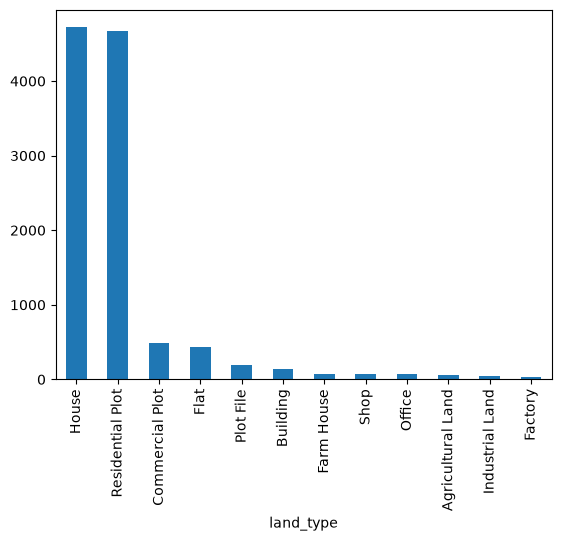

In [7]:
df["land_type"].value_counts().plot(kind="bar")
plt.show()

**TODO 8:** For each `land_type`, compute the **total** `price_cr` and the **total** `area_value` (via `groupby(...).sum()`), then compute price-per-marla as `total_price / total_area` for each type. Sort the result and plot it as a bar chart.

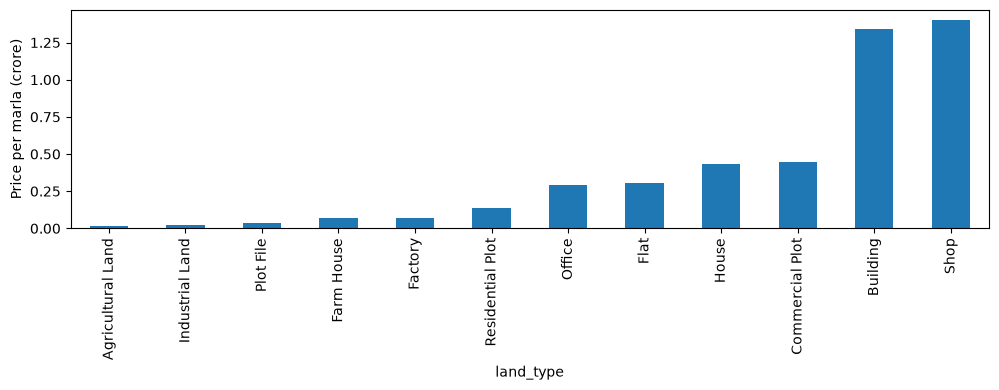

In [8]:
totals = df.groupby("land_type")[["price_cr", "area_value"]].sum()
price_per_marla = (totals["price_cr"] / totals["area_value"]).sort_values()
price_per_marla.plot(kind="bar", figsize=(10, 4))
plt.ylabel("Price per marla (crore)")
plt.tight_layout()
plt.show()

**TODO 9:** Display that same price-per-marla series sorted in **descending** order.

In [9]:
print(price_per_marla.sort_values(ascending=False))

land_type
Shop                 1.398802
Building             1.343630
Commercial Plot      0.446479
House                0.436162
Flat                 0.305909
Office               0.293990
Residential Plot     0.137510
Factory              0.070522
Farm House           0.066636
Plot File            0.038984
Industrial Land      0.025449
Agricultural Land    0.014393
dtype: float64


### Grouping land types into broader categories

**TODO 10:** Define four lists grouping the land types into broader categories:
- `residential = ["House", "Flat", "Residential Plot"]`
- `commercial = ["Building", "Shop", "Office", "Commercial Plot"]`
- `agricultural = ["Plot File", "Farm House", "Agricultural Land"]`
- `industrial = ["Factory", "Industrial Land"]`

In [10]:
residential = ["House", "Flat", "Residential Plot"]
commercial = ["Building", "Shop", "Office", "Commercial Plot"]
agricultural = ["Plot File", "Farm House", "Agricultural Land"]
industrial = ["Factory", "Industrial Land"]

**TODO 11:** Using the price-per-marla series from the earlier task, show only the values for `residential` and `commercial` land types (hint: `.isin([...])`). Compare them.

In [11]:
print(price_per_marla[price_per_marla.index.isin(residential + commercial)].sort_values(ascending=False))

land_type
Shop                1.398802
Building            1.343630
Commercial Plot     0.446479
House               0.436162
Flat                0.305909
Office              0.293990
Residential Plot    0.137510
dtype: float64


**TODO 12:** Show only the price-per-marla values for `agricultural` land types.

In [12]:
print(price_per_marla[price_per_marla.index.isin(agricultural)].sort_values(ascending=False))

land_type
Farm House           0.066636
Plot File            0.038984
Agricultural Land    0.014393
dtype: float64


**TODO 13:** Show only the price-per-marla values for `industrial` land types.

In [13]:
print(price_per_marla[price_per_marla.index.isin(industrial)].sort_values(ascending=False))

land_type
Factory            0.070522
Industrial Land    0.025449
dtype: float64


## Preparing a working dataframe

**TODO 14:** Create `df1` by dropping the columns `location`, `price`, `area`, `added_days`, and `purpose` from `df` (we'll use the already-cleaned versions of these instead).

In [14]:
df1 = df.drop(columns=["location", "price", "area", "added_days", "purpose"])

**TODO 15:** Rename the `locat` column in `df1` to `location`.

In [15]:
df1 = df1.rename(columns={"locat": "location"})

**TODO 16:** Split `df1` into four separate dataframes, using the category lists you defined earlier and filtering on `land_type`:
`residential_df`, `commercial_df`, `agricultural_df`, `industrial_df`.

In [16]:
residential_df = df1[df1["land_type"].isin(residential)].copy()
commercial_df = df1[df1["land_type"].isin(commercial)].copy()
agricultural_df = df1[df1["land_type"].isin(agricultural)].copy()
industrial_df = df1[df1["land_type"].isin(industrial)].copy()
print(residential_df.shape, commercial_df.shape, agricultural_df.shape, industrial_df.shape)

(9828, 6) (754, 6) (326, 6) (75, 6)


## EDA on `residential_df` — Univariate Analysis

### Categorical columns: `land_type`

**TODO 17:** Plot a bar chart (figsize `(5,4)`) of the `land_type` value counts **within `residential_df`**.

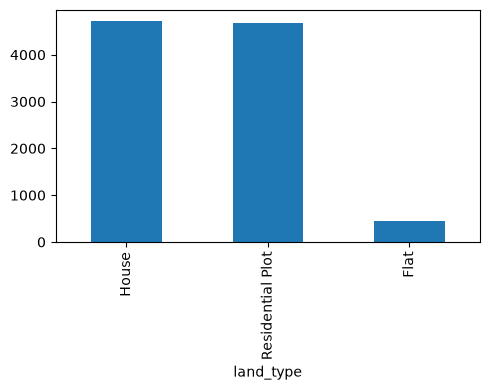

In [17]:
plt.figure(figsize=(5, 4))
residential_df["land_type"].value_counts().plot(kind="bar")
plt.tight_layout()
plt.show()

**TODO 18:** Compute the percentage share of each `land_type` within `residential_df` (count of each type divided by total rows, ×100).

In [18]:
print(residential_df["land_type"].value_counts() / len(residential_df) * 100)

land_type
House               48.026048
Residential Plot    47.507123
Flat                 4.466829
Name: count, dtype: float64


**TODO 19 (reflection):** Based on the percentages above, write 2–3 bullet points on which land types dominate the residential segment, and roughly by how much.

- Houses and residential plots dominate this segment, at about 48% and 47.5% of residential listings.
- Flats are a small share, about 4.5%.
- Together, houses and residential plots account for roughly 95% of the residential rows.

### `location` column

**TODO 20:** Check the `location` value counts within `residential_df`.

In [19]:
print(residential_df["location"].value_counts())

location
DHA Defence                                                    1920
Bahria Town                                                     682
Raiwind Road                                                    544
GT Road                                                         363
Park View City                                                  308
Bahria Orchard                                                  264
Askari                                                          243
Johar Town                                                      224
Paragon City                                                    197
Central Park Housing Scheme                                     180
LDA Avenue                                                      159
Gulberg                                                         144
Al Rehman Garden                                                143
DHA 11 Rahbar                                                   137
Allama Iqbal Town                      

**TODO 21:** Check the **normalized** (percentage) value counts of `location`, top 10 only.

In [20]:
print(residential_df["location"].value_counts(normalize=True).head(10))

location
DHA Defence                    0.195360
Bahria Town                    0.069394
Raiwind Road                   0.055352
GT Road                        0.036935
Park View City                 0.031339
Bahria Orchard                 0.026862
Askari                         0.024725
Johar Town                     0.022792
Paragon City                   0.020045
Central Park Housing Scheme    0.018315
Name: proportion, dtype: float64


**TODO 22:** `location` is a high-cardinality column. Find how many distinct locations occur **fewer than 10 times**.

In [21]:
print((residential_df["location"].value_counts() < 10).sum())

234


**TODO 23:** A common rule of thumb: categories making up less than roughly 0.01% of rows can be grouped into `"Others"`. Find `location` categories with fewer than 40 occurrences, and replace them with `"Others"` in `residential_df["location"]`.

In [22]:
location_counts = residential_df["location"].value_counts()
rare_locations = location_counts[location_counts < 40].index
residential_df["location"] = residential_df["location"].replace(rare_locations, "Others")
print(residential_df["location"].value_counts().head())

location
DHA Defence     1920
Others          1667
Bahria Town      682
Raiwind Road     544
GT Road          363
Name: count, dtype: int64


**TODO 24:** Create a **mean target encoding** for `location`: group `residential_df` by `location`, take the mean of `price_cr`, and map those means back onto a new column `location_encoded`.

In [23]:
location_means = residential_df.groupby("location")["price_cr"].mean()
residential_df["location_encoded"] = residential_df["location"].map(location_means)

**TODO 25:** Preview a few sample rows to confirm the new column looks right.

In [24]:
print(residential_df[["location", "location_encoded", "price_cr"]].sample(5, random_state=42))

                          location  location_encoded  price_cr
18154                       Others          2.511239     0.600
20120                      GT Road          0.927890     0.175
14209                  Bahria Town          2.667322     1.850
15867            Allama Iqbal Town          3.466222     2.350
3060   Central Park Housing Scheme          1.451389     0.500


## Numerical columns
### `price_cr`

**TODO 26:** Get summary statistics (`.describe()`) for `price_cr` in `residential_df`. Compare the mean to the median — what does the gap suggest?

In [25]:
print(residential_df["price_cr"].describe())
print("The mean is higher than the median, so a few very expensive listings are pulling the average up.")

count    9828.000000
mean        3.677383
std         6.612533
min         0.010500
25%         0.900000
50%         2.000000
75%         4.000000
max       180.000000
Name: price_cr, dtype: float64
The mean is higher than the median, so a few very expensive listings are pulling the average up.


**TODO 27:** Plot a histogram of `price_cr` (100 bins, with KDE).

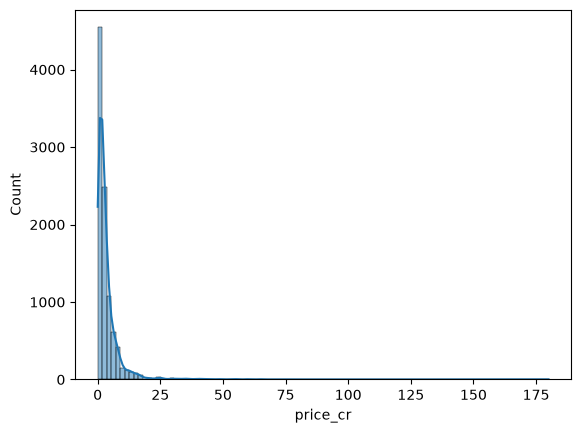

In [26]:
sns.histplot(residential_df["price_cr"], bins=100, kde=True)
plt.show()

**TODO 28:** Plot the same histogram again, but with a **log-scaled** x-axis (`log_scale=True`).

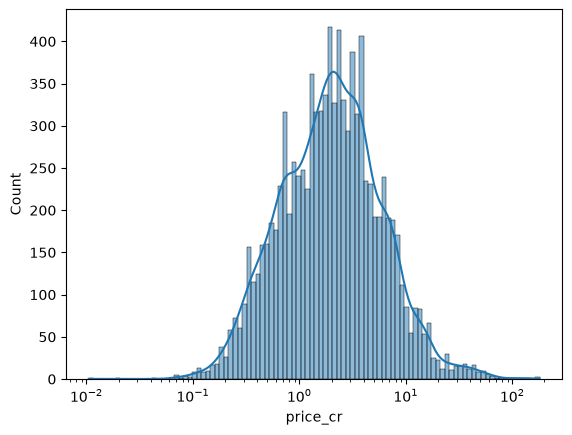

In [27]:
sns.histplot(residential_df["price_cr"], bins=100, kde=True, log_scale=True)
plt.show()

**TODO 29 (reflection):** Is `price_cr` left-skewed or right-skewed? What does that tell you about typical vs. extreme listing prices?

price_cr is right-skewed. The mean (about 3.68 crore) is well above the median (2 crore), so a typical listing is cheaper than the average and a long tail of very expensive properties pulls the mean up.

**TODO 30:** Plot a boxplot of `price_cr` to visualize outliers.

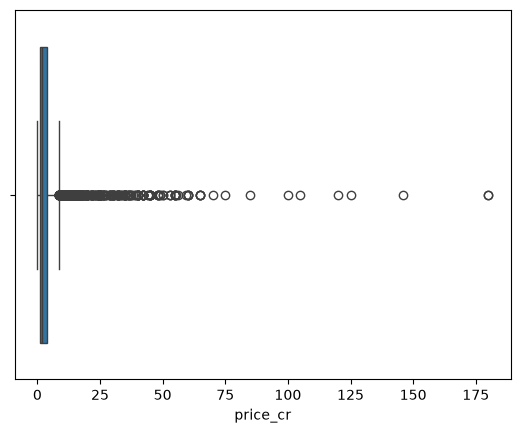

In [28]:
sns.boxplot(x=residential_df["price_cr"])
plt.show()

**TODO 31:** Filter rows where `price_cr > 50` into a new dataframe `df_50`, then compute a new column `price_per_marla = price_cr / area_value` for that subset.

In [29]:
df_50 = residential_df[residential_df["price_cr"] > 50].copy()
df_50["price_per_marla"] = df_50["price_cr"] / df_50["area_value"]
print(df_50[["land_type", "price_cr", "area_value", "price_per_marla"]].head())

             land_type  price_cr  area_value  price_per_marla
17    Residential Plot      60.0       140.0         0.428571
1030             House      53.0        40.0         1.325000
2587             House      75.0       140.0         0.535714
2588             House      60.0        80.0         0.750000
2598             House      65.0       120.0         0.541667


**TODO 32:** Compute the skewness of `price_cr` (`.skew()`).

In [30]:
print(residential_df["price_cr"].skew())

9.875798453101199


**TODO 33:** Compute the kurtosis of `price_cr` (`.kurt()`).

In [31]:
print(residential_df["price_cr"].kurt())

175.29565080934114


**TODO 34:** Plot a boxplot of `price_cr` **grouped by `land_type`** (x = `land_type`, y = `price_cr`), showing outliers, with x-axis labels rotated 90°, a log-scaled y-axis, and a title + axis labels.

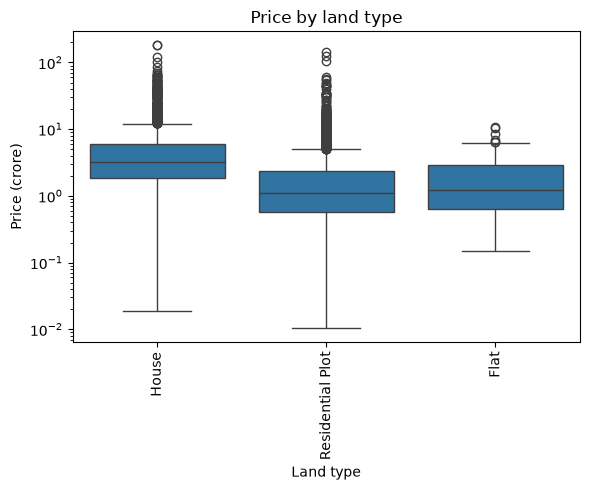

In [32]:
plt.figure(figsize=(6, 5))
sns.boxplot(data=residential_df, x="land_type", y="price_cr")
plt.xticks(rotation=90)
plt.yscale("log")
plt.title("Price by land type")
plt.xlabel("Land type")
plt.ylabel("Price (crore)")
plt.tight_layout()
plt.show()

**TODO 35:** Compute the standard deviation of `price_cr`, grouped by `land_type`.

In [33]:
print(residential_df.groupby("land_type")["price_cr"].std())

land_type
Flat                1.554054
House               7.888587
Residential Plot    4.894253
Name: price_cr, dtype: float64


**TODO 36 (reflection):** Based on the spread (std) per land type from the previous task, which land types are the most scattered/variable in price? What might that imply for modeling (e.g. would separate models, or a different target like price-per-marla, make sense for those types)?

Houses have the widest price spread (standard deviation about 7.9 crore), followed by residential plots (about 4.9). Flats are much tighter (about 1.6). A single model on raw price will be driven by the extreme house listings, so a log price or a price-per-marla target, or separate models by land type, fits the more variable types better.

### Reducing skew with a log transform

**TODO 37:** Create a new column `log_price = np.log1p(price_cr)`.

In [34]:
residential_df["log_price"] = np.log1p(residential_df["price_cr"])

**TODO 38:** Plot a boxplot of `log_price`. Compare it to the boxplot of raw `price_cr` from before — did the log transform help reduce the spread of outliers?

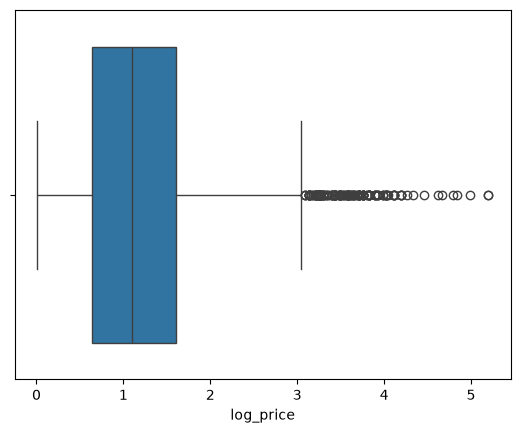

In [35]:
sns.boxplot(x=residential_df["log_price"])
plt.show()

**TODO 39:** Compute the standard deviation of `log_price`, grouped by `land_type`, and compare it to the std of raw `price_cr` per land type from before.

In [36]:
print(residential_df.groupby("land_type")["log_price"].std())

land_type
Flat                0.496626
House               0.676164
Residential Plot    0.613260
Name: log_price, dtype: float64


**TODO 40:** Plot a histogram (with KDE) of `log_price`.

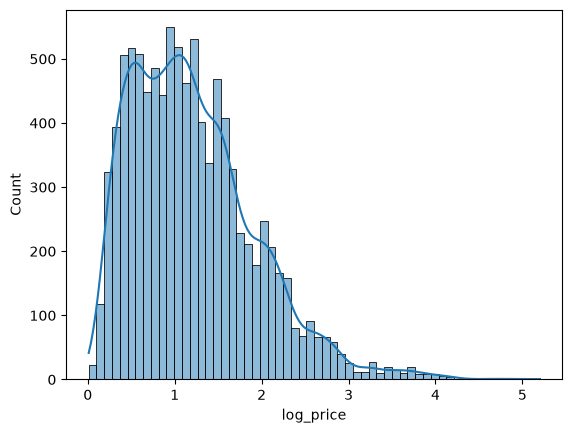

In [37]:
sns.histplot(residential_df["log_price"], kde=True)
plt.show()

**TODO 41:** Preview a random sample of 5 rows.

In [38]:
print(residential_df.sample(5, random_state=42))

              land_type  price_cr                     location  baths  \
18154             House     0.600                       Others      3   
20120  Residential Plot     0.175                      GT Road      0   
14209             House     1.850                  Bahria Town      4   
15867             House     2.350            Allama Iqbal Town      4   
3060   Residential Plot     0.500  Central Park Housing Scheme      0   

       area_value  bed  location_encoded  log_price  
18154         2.0    3          2.511239   0.470004  
20120         5.0    0          0.927890   0.161268  
14209         5.0    3          2.667322   1.047319  
15867         5.0    4          3.466222   1.208960  
3060          5.0    0          1.451389   0.405465  


### Focusing on `Residential Plot` listings

**TODO 42:** Filter `residential_df` down to rows where `land_type == "Residential Plot"` only, and store the result in a new variable (e.g. `residential_plot_df`).

In [39]:
residential_plot_df = residential_df[residential_df["land_type"] == "Residential Plot"].copy()

**TODO 43:** Compute `price_per_marla = price_cr / area_value` (rounded to 2 decimals) for this subset.

In [40]:
residential_plot_df["price_per_marla"] = (residential_plot_df["price_cr"] / residential_plot_df["area_value"]).round(2)

**TODO 44:** Preview a random sample of 5 rows.

In [41]:
print(residential_plot_df.sample(5, random_state=42))

              land_type  price_cr       location  baths  area_value  bed  \
12010  Residential Plot      0.33         Others      0         5.0    0   
20411  Residential Plot      0.27   Raiwind Road      0         3.0    0   
4555   Residential Plot      0.53         Others      0         4.0    0   
6480   Residential Plot      7.50    DHA Defence      0        40.0    0   
20039  Residential Plot      1.20  DHA 11 Rahbar      0         8.0    0   

       location_encoded  log_price  price_per_marla  
12010          2.511239   0.285179             0.07  
20411          1.752350   0.239017             0.09  
4555           2.511239   0.425268             0.13  
6480           6.713888   2.140066             0.19  
20039          1.924635   0.788457             0.15  


**TODO 45:** Plot a histogram (50 bins, with KDE) of `price_per_marla`.

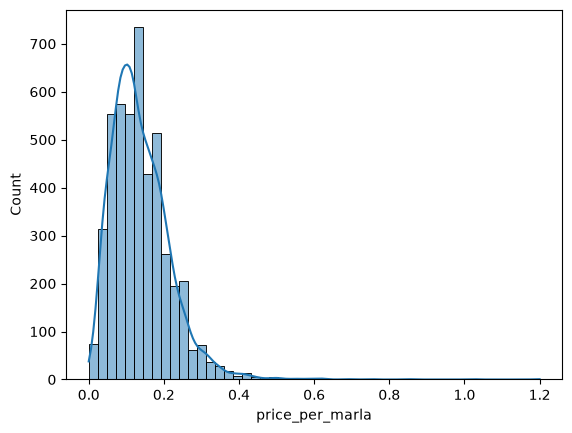

In [42]:
sns.histplot(residential_plot_df["price_per_marla"], bins=50, kde=True)
plt.show()

**TODO 46:** Plot a boxplot of `price_per_marla`.

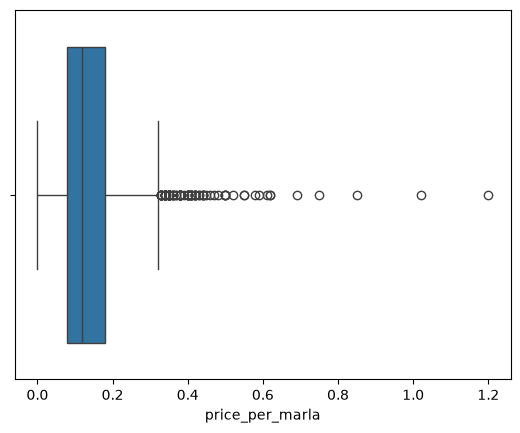

In [43]:
sns.boxplot(x=residential_plot_df["price_per_marla"])
plt.show()

**TODO 47:** Investigate rows where `price_per_marla >= 1` — these look like possible outliers or data errors. Inspect them.

In [44]:
high_ppm = residential_plot_df[residential_plot_df["price_per_marla"] >= 1]
print(high_ppm)
print(high_ppm.isnull().sum())

              land_type  price_cr              location  baths  area_value  \
10029  Residential Plot    0.4195  Main Canal Bank Road      0         0.0   
10251  Residential Plot   48.0000               Gulberg      0        40.0   
17355  Residential Plot    5.1000        Ferozepur Road      0         5.0   

       bed  location_encoded  log_price  price_per_marla  
10029    0          1.459630   0.350305              inf  
10251    0         16.565347   3.891820             1.20  
17355    0          0.926902   1.808289             1.02  
land_type           0
price_cr            0
location            0
baths               0
area_value          0
bed                 0
location_encoded    0
log_price           0
price_per_marla     0
dtype: int64


**TODO 48:** If any rows you found above have null values, drop them.

In [45]:
residential_plot_df = residential_plot_df.drop(index=high_ppm[high_ppm.isnull().any(axis=1)].index)

**TODO 49:** Compute the standard deviation of `price_per_marla` after this cleanup.

In [46]:
print(residential_plot_df["price_per_marla"].std())

nan


C:\Users\A\AppData\Local\Temp\netsol_venv\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


## Final prep for modeling

**TODO 50:** Drop the columns that are no longer needed for modeling: `land_type`, `location_encoded`, `log_price`, `baths`, and `bed`.

In [47]:
residential_plot_df = residential_plot_df.drop(columns=["land_type", "location_encoded", "log_price", "baths", "bed"])
print(residential_plot_df.head())

    price_cr     location  area_value  price_per_marla
4       7.25       Others        20.0             0.36
13     25.00      Gulberg        40.0             0.62
14     45.00       Others       110.0             0.41
17     60.00       Others       140.0             0.43
19      3.10  DHA Defence        10.0             0.31


**TODO 51:** Install and import what you'll need for modeling next: `train_test_split` and `LinearRegression` from scikit-learn, `DecisionTreeRegressor` from `sklearn.tree`, and the `category_encoders` package (`pip install category_encoders`, then `import category_encoders as ce`) for encoding categorical variables.

In [48]:
%pip install -q category_encoders
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
import category_encoders as ce
print(train_test_split, LinearRegression, DecisionTreeRegressor, ce)


[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: C:\Users\A\AppData\Local\Temp\netsol_venv\Scripts\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


<function train_test_split at 0x000001778B4F0220> <class 'sklearn.linear_model._base.LinearRegression'> <class 'sklearn.tree._classes.DecisionTreeRegressor'> <module 'category_encoders' from 'C:\\Users\\A\\AppData\\Local\\Temp\\netsol_venv\\Lib\\site-packages\\category_encoders\\__init__.py'>
